# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm Logistic Regression
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 13th October 2026*

---

## Research question

**Can the time of day help predict which of my ten most-listened-to artists I will listen to?**

This notebook uses Last.fm scrobbles to test whether listening time contains a useful signal about artist choice. 

It treats artist as a ten-class prediction problem

The analysis is limited to my ten most-scrobbled artists and uses time of day as the model feature


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression

scrobbles = pd.read_csv('../datasets/scrobbles.csv')

## Define the artist set

Ten artists with the highest scrobble counts are selected and displayed in the table below shows their listening counts and how their share varies across the four time-of-day categories.

**Question:** Are some of these artists more common at particular times of day?

In [2]:
top_artists = scrobbles['artist'].value_counts().head(10).index
subset = scrobbles[scrobbles['artist'].isin(top_artists)].copy()


print(subset['artist'].value_counts())
print(pd.crosstab(subset['tod'], subset['artist'], normalize='index').round(2))

artist
Arctic Monkeys           2230
Tame Impala              2042
Red Hot Chili Peppers    1559
Portishead               1199
Alice in Chains          1108
John Mayer                892
Ghost                     572
Morcheeba                 562
Pink Floyd                509
Massive Attack            500
Name: count, dtype: int64
artist     Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
tod                                                                             
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
morning               0.12            0.11   0.11        0.02            0.08   
night                 0.06            0.27   0.00        0.14            0.02   

artist     Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
tod                                                                   
afternoon       0.03        0.04      

I encode `tod` as one-hot features and use the artist name as the target. The data is split into training and test sets, preserving each artist's share in both sets (`stratify=y`)

The pd.get_dummies() function is used to perform one-hot encoding on the `tod` column, converting it into binary indicator variables suitable for logistic regression. I followed [GeeksforGeeks'](https://www.geeksforgeeks.org/machine-learning/ml-one-hot-encoding/) tutorial for implementing this, see [also](https://www.geeksforgeeks.org/pandas/python-pandas-get_dummies-method/) 

I compare the model's test accuracy with a baseline that predicts the most common artist in the data. The classification report also shows precision, recall, and F1-score for each artist, which helps reveal whether accuracy hides poor results for less frequent artists

### Variable guide

- `X`: `pd.get_dummies` turns each time-of-day category into its own 0/1 column
- `y`: the **answer to predict** for each row: the artist name
- `X_train`, `y_train`: the input rows and correct artist labels used to teach the model
- `X_test`, `y_test`: separate input rows and labels held back to check how well the model predicts unfamiliar plays
- `test_size=0.2`: 20% of the rows for that check the remaining 80% train the model
- `random_state=42`: rerunning the notebook uses the same split
- `stratify=y`: keep roughly the same proportion of each artist in the training and test sets. Ref: [Geeksforgeeks](https://www.geeksforgeeks.org/machine-learning/understanding-the-predictproba-function-in-scikit-learns-svc/)
- `log_regress`: classify multiple categories, with one artist as each category (logistic regression)
- `max_iter=1000`: allow the model up to 1,000 training steps to find its coefficients
- `baseline`: the most common artist in the training rows. predicting this artist every time gives a simple comparison point
- `accuracy_score()`: the fraction of predictions that were correct. The baseline call compares `y_test` against the same `baseline` guess for every row
- `classification_report()`: **Precision** is how often predictions for an artist were right, **recall** is how many of that artist's actual plays were found. **F1-score** balances precision and recall, **support** is the number of actual test rows for that artist
- `zero_division=0`: show a score of zero instead of showing a warning

`log_regress` learns to use the `X`  to predict the `y`


In [3]:
# get dummies referenced from https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/03.10-Working-With-Strings.ipynb
X = pd.get_dummies(subset['tod']).astype(int)
y = subset['artist']

# followed Hyperparameters-and-Model-Validation.ipynb from example PythonDataScienceHanbook repo in class
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# logistic regression is used here for this Last.fm multiclass prediction
log_regress = LogisticRegression(max_iter=1000)
log_regress.fit(X_train, y_train)
y_pred = log_regress.predict(X_test)

baseline = y_train.value_counts().idxmax()
print('Baseline accuracy:', accuracy_score(y_test, [baseline] * len(y_test)))
print('Model accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Baseline accuracy: 0.19955257270693513
Model accuracy: 0.23355704697986576
                       precision    recall  f1-score   support

      Alice in Chains       0.00      0.00      0.00       222
       Arctic Monkeys       0.23      0.57      0.33       446
                Ghost       0.00      0.00      0.00       114
           John Mayer       0.00      0.00      0.00       178
       Massive Attack       0.00      0.00      0.00       100
            Morcheeba       0.00      0.00      0.00       112
           Pink Floyd       0.00      0.00      0.00       102
           Portishead       0.00      0.00      0.00       240
Red Hot Chili Peppers       0.00      0.00      0.00       312
          Tame Impala       0.23      0.65      0.34       409

             accuracy                           0.23      2235
            macro avg       0.05      0.12      0.07      2235
         weighted avg       0.09      0.23      0.13      2235



### Multiclass result

The model reaches **23.4% test accuracy**, compared with **20.0%** for the most-common-artist baseline. That is a gain of about **3.4 percentage points**, so time of day adds only a small amount of predictive value overall.

The per-artist report gives a more important warning: the model has non-zero precision and recall for only Arctic Monkeys and Tame Impala, and scores zero for the other eight artists. The overall accuracy therefore overstates how useful the model is across the full set of artists.

**Takeaway:** time of day alone does not reliably identify which of the ten artists will be played. The probability table below shows the model's estimated distribution for each time category, rather than a dependable recommendation.

- `buckets`: one made-up input row for each time-of-day category, with a 1 for that category and 0 for the others. These rows let the model estimate artist probabilities for morning, afternoon, evening, and night, even without passing real listening records
- `np.eye()` creates one-hot pattern, the row and column labels are the time categories
- `probs`: probability table returned by the model, one row per time category and a column per artist. `predict_proba` gives the estimated probability of each artist for each `buckets` row
- `y_pred`: artists names train model predicts

           Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
morning               0.12            0.11   0.10        0.02            0.07   
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
night                 0.06            0.27   0.01        0.14            0.02   

           Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
morning         0.05        0.01        0.09                   0.11   
afternoon       0.03        0.04        0.08                   0.16   
evening         0.06        0.06        0.14                   0.14   
night           0.10        0.09        0.10                   0.04   

           Tame Impala  
morning           0.31  
afternoon         0.21  
evening           0.13  
night             0.17  


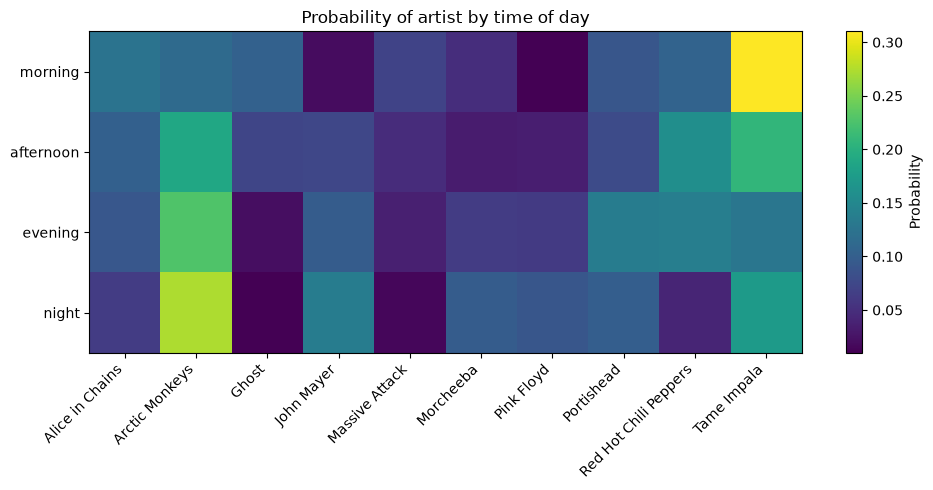

In [4]:
buckets = pd.DataFrame(np.eye(len(X.columns), dtype=int), columns=X.columns, index=X.columns)
probs = pd.DataFrame(log_regress.predict_proba(buckets), columns=log_regress.classes_, index=buckets.index)
probs = probs.reindex(['morning', 'afternoon', 'evening', 'night'])
print(probs.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(probs.values, aspect='auto')
ax.set_xticks(range(len(probs.columns)))
ax.set_xticklabels(probs.columns, rotation=45, ha='right')
ax.set_yticks(range(len(probs.index)))
ax.set_yticklabels(probs.index)
fig.colorbar(im, label='Probability')
ax.set_title('Probability of artist by time of day')
plt.tight_layout()
plt.show()

In [5]:
merged = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

# keep the same ten artists, rebuild the subset from the merged data
top_artists = merged['artist'].value_counts().head(10).index
subset_ml = merged[merged['artist'].isin(top_artists)].copy()

print(subset_ml['is_loved'].value_counts(normalize=True).round(3))

is_loved
0    0.932
1    0.068
Name: proportion, dtype: float64


## Result

For the ten-class question, the model improves on the majority-artist baseline by only about 3.4 percentage points and fails to identify eight artists in the test set. Time of day alone is therefore a weak predictor of the specific artist.

**Answer to the research question:** listening time contains some signal, especially for a few artists, but it is not enough on its own to reliably predict artist choice. Day of week, listening history, or additional context could be tested as further features

## Metal or not metal from audio features

**Question:** can the Spotify audio features of a track tell me if the artist is metal?

The genre tags belong to the artist, not the track. A track is metal (1) if any of its artist's genre tags contain the word "metal", otherwise it is not metal (0). Artists with no genre tags are dropped

The audio features are scaled with `StandardScaler`, as `loudness`, `tempo` and `duration` are on much bigger scales than the 0 - 1 features. The scaler is only fitted on the training data so nothing from the test set leaks in

In [5]:
from sklearn.model_selection import cross_val_score, GroupKFold
from sklearn.pipeline import make_pipeline

merged = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']

# some artists have no genre tags, drop them
genre_data = merged.dropna(subset=['artist_genres']).copy()

# 1 if any of the artist's genre tags contains "metal", else 0
genre_data['is_metal'] = genre_data['artist_genres'].str.contains('metal').astype(int)

print(f"Tracks with genre tags: {len(genre_data)}")
print(genre_data['is_metal'].value_counts(normalize=True).round(3))

X = genre_data[audio]
y = genre_data['is_metal']

# followed Hyperparameters-and-Model-Validation.ipynb from example PythonDataScienceHanbook repo in class
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# fit the scaler on the training data only so nothing from the test set leaks in
scaler = StandardScaler().fit(X_train)
metal_model = LogisticRegression(max_iter=1000)
metal_model.fit(scaler.transform(X_train), y_train)
y_pred = metal_model.predict(scaler.transform(X_test))

baseline = y_train.value_counts().idxmax()
print('Baseline accuracy:', round(accuracy_score(y_test, [baseline] * len(y_test)), 3))
print('Model accuracy:   ', round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, target_names=['not metal', 'metal']))

# positive = more likely metal, negative = less likely (features are scaled so these are comparable)
print(pd.Series(metal_model.coef_[0], index=audio).round(2).sort_values())

Tracks with genre tags: 1744
is_metal
1    0.505
0    0.495
Name: proportion, dtype: float64
Baseline accuracy: 0.504
Model accuracy:    0.708
              precision    recall  f1-score   support

   not metal       0.72      0.68      0.70       173
       metal       0.70      0.74      0.72       176

    accuracy                           0.71       349
   macro avg       0.71      0.71      0.71       349
weighted avg       0.71      0.71      0.71       349

acousticness       -0.41
danceability       -0.40
valence            -0.25
loudness           -0.25
liveness           -0.06
instrumentalness   -0.05
tempo              -0.03
speechiness         0.08
duration            0.14
energy              0.62
dtype: float64


In [7]:
# the same artist appears in both the train and test sets above, which can inflate the score
# so score again with every artist kept in a single fold
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(pipe, X, y, cv=GroupKFold(n_splits=5), groups=genre_data['artist'])
print('Accuracy per fold:', scores.round(3))
print('Mean accuracy by artist:', round(scores.mean(), 3))

Accuracy per fold: [0.327 0.645 0.771 0.662 0.356]
Mean accuracy by artist: 0.552


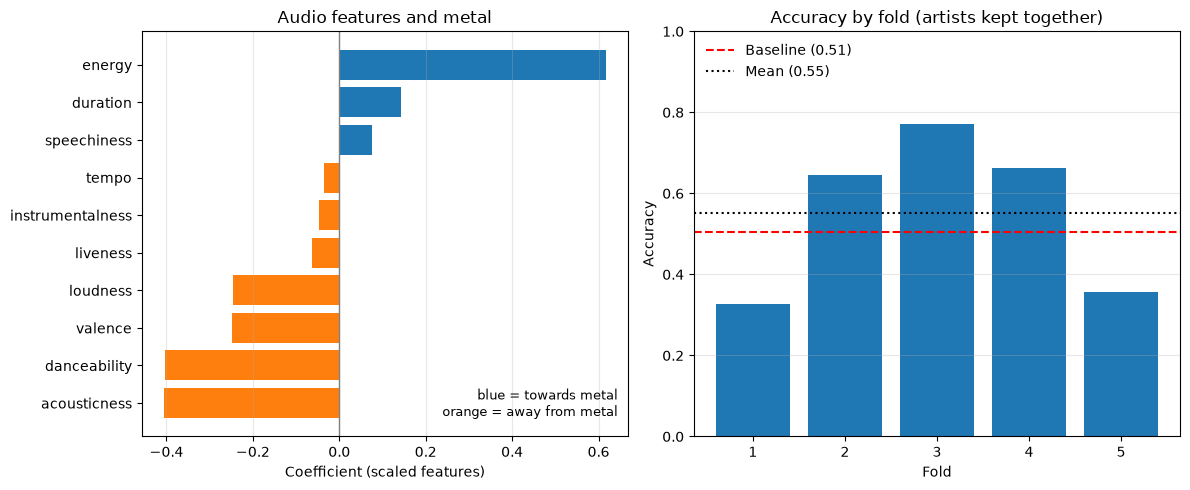

In [8]:
# which audio features point towards metal (blue) or away from it (orange)
coefs = pd.Series(metal_model.coef_[0], index=audio).sort_values()
colors = ['tab:orange' if c < 0 else 'tab:blue' for c in coefs]

# always guessing the more common class (about 50%)
baseline = y.value_counts(normalize=True).max()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# left - coefficients from the metal model
ax1.barh(coefs.index, coefs.values, color=colors)
ax1.axvline(0, color='grey', lw=1)
ax1.set(title='Audio features and metal', xlabel='Coefficient (scaled features)')
ax1.grid(True, axis='x', alpha=0.3)
ax1.text(0.98, 0.04, 'blue = towards metal\norange = away from metal',
         transform=ax1.transAxes, ha='right', va='bottom', fontsize=9)

# right - accuracy when each artist is kept in one fold, against always guessing one class
ax2.bar(range(1, len(scores) + 1), scores, color='tab:blue')
ax2.axhline(baseline, color='red', ls='--', label=f'Baseline ({baseline:.2f})')
ax2.axhline(scores.mean(), color='black', ls=':', label=f'Mean ({scores.mean():.2f})')
ax2.set(title='Accuracy by fold (artists kept together)', xlabel='Fold', ylabel='Accuracy', ylim=(0, 1))
ax2.set_xticks(range(1, len(scores) + 1))
ax2.legend(frameon=False, loc='upper left')
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Result: metal or not metal

About half of the tracks are metal (50.5%), so always guessing one class is right about 50% of the time. The model gets **70.8%** on the test set, which looks like a good improvement. It finds metal (recall 0.74) and not metal (recall 0.68) about equally well. `energy` is the biggest sign of metal, while `acousticness` and `danceability` point away from it.

The genre tags belong to the artist, so every track by an artist has the same label, and the same artist ends up in both the train and test sets. The model can partly learn what an artist sounds like instead of what metal sounds like.

To check, I kept each artist's tracks together in one fold. The accuracy drops to **55.2%** and jumps around a lot between folds (33% to 77%)

**Takeaway:** audio features do give some signal for metal, mainly `energy`, but much less than the first score suggests. To do better I would need more artists, a better way to label genre, or more features